### TASK 1

In [57]:
# Import pandas for loading and analysing the dataset
import pandas as pd

# Load the medical insurance dataset into a DataFrame
df = pd.read_csv("insurance.csv")

# Display the first five rows to inspect the dataset
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [58]:
# Check the structure of the dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [59]:
# Check whether the dataset contains any duplicate records
df.duplicated().sum()

np.int64(1)

In [54]:
# Remove duplicate records from the dataset
df = df.drop_duplicates()

# Check the dataset size after removing the duplicate
df.shape

(1337, 7)

In [20]:
# Check the number of missing values in each column
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### Missing Values

The dataset contains no missing values across any of the seven variables.

### Data Suitability

The dataset initially  contained 1338 records and 7 variables. Four variables (age, bmi, children and charges) are numerical, while three variables (sex, smoker and region) are categorical.The dataset is suitable for applying a Linear Regression model because the target variable, charges, is numerical and continuous. The dataset contains both numerical and categorical predictor variables that can be used to explain differences in medical charges.
After removing one duplicate record, the dataset contains 1337 observations and 7 variables. There are no missing values, although the categorical variables need to be converted into numerical form before they can be used in the regression model.
The dataset is therefore suitable for the analysis

In [21]:
# summary statistics for the numerical variables
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


### Summary Statistics

The numerical variables show  variation across the dataset. Age ranges from 18 to 64 years, while bmi ranges from 15.96 to 53.13. The number of children ranges from 0 to 5. Medical charges range from approximately 1121.87 to 63770.43.
The large range in medical charges, together with the difference between the mean and maximum values, suggests that some observations may have unusually high charges. 

In [22]:
# Check the number of observations in each category
# This helps us understand the distribution of the categorical variables

print("Sex:")
print(df["sex"].value_counts())

print("\nSmoking status:")
print(df["smoker"].value_counts())

print("\nRegion:")
print(df["region"].value_counts())

Sex:
sex
male      675
female    662
Name: count, dtype: int64

Smoking status:
smoker
no     1063
yes     274
Name: count, dtype: int64

Region:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


### Categorical Variables

The categorical variables contain consistent and clearly defined categories. Sex is balanced between males and females. The dataset contains more non-smokers than smokers, while the four geographical regions have fairly similar numbers of observations.
They will need to be encoded into numerical values before being used in the Linear Regression model.

### VISUAL EDA

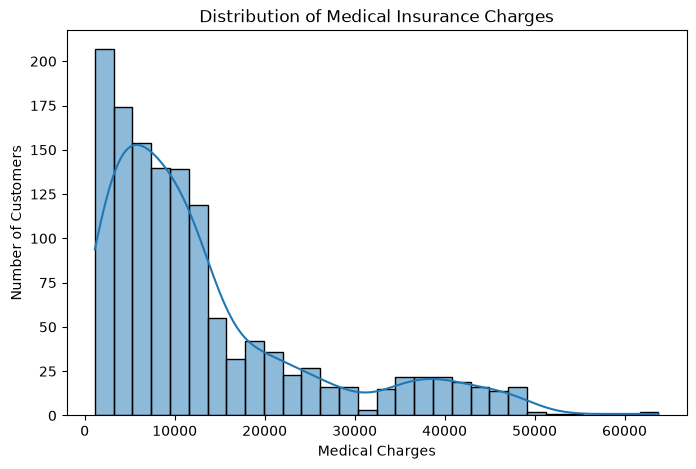

In [23]:
# Import libraries for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of medical insurance charges
plt.figure(figsize=(8, 5))
sns.histplot(df["charges"], bins=30, kde=True)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical Charges")
plt.ylabel("Number of Customers")
plt.show()

### Distribution of Medical Charges
The distribution of medical charges is right-skewed, with most observations concentrated at lower charge values and fewer observations having higher charges.
This indicates that medical charges are not evenly distributed across customers.

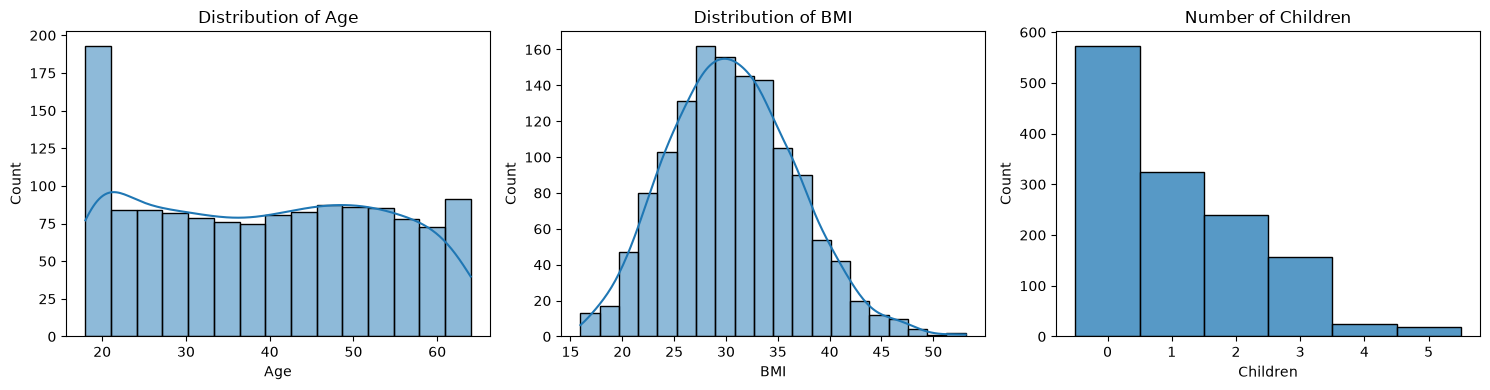

In [24]:
# Plot the distributions of the numerical predictor variables

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["age"], bins=15, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Age")
axes[0].set_xlabel("Age")

sns.histplot(df["bmi"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Distribution of BMI")
axes[1].set_xlabel("BMI")

sns.histplot(df["children"], discrete=True, ax=axes[2])
axes[2].set_title("Number of Children")
axes[2].set_xlabel("Children")

plt.tight_layout()
plt.show()

### Numerical Variable Distributions
 This helps us understand their spread and identify possible unusual values. The distributions show variation in age, bmi and the number of children across customers. Age covers a broad range, bmi varies between individuals and the number of children is concentrated around lower values.

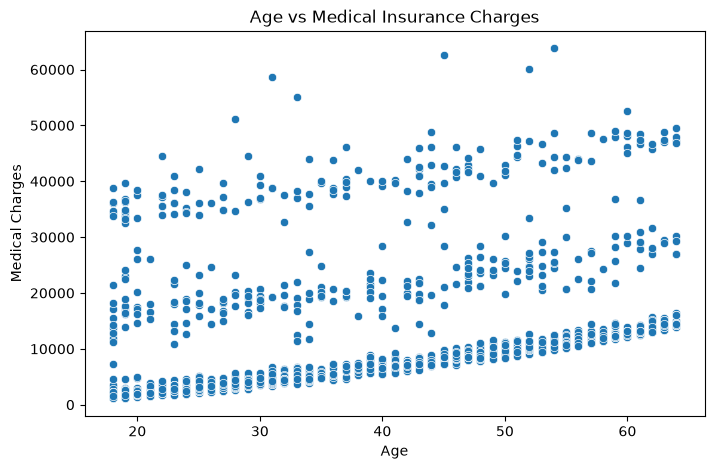

In [25]:
# Plot age against medical charges

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges")

plt.title("Age vs Medical Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Medical Charges")
plt.show()

### Age and Medical Charges
The scatterplot shows a positive relationship between age and medical charges. 
This suggests that age may be a useful predictor of medical charges.

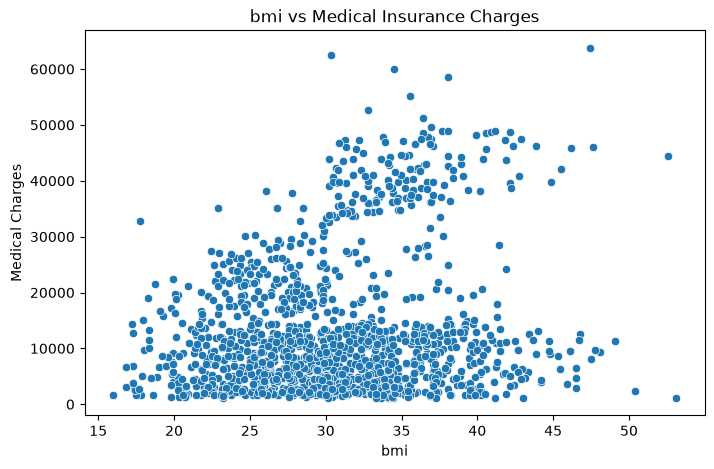

In [26]:
# Plot BMI against medical charges
# This helps us assess whether BMI has a useful relationship with the target variable

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="charges")

plt.title("bmi vs Medical Insurance Charges")
plt.xlabel("bmi")
plt.ylabel("Medical Charges")
plt.show()

### bmi and Medical Charges
The scatterplot indicates a positive relationship between bmi and medical charges.
This suggests that mbi may provide useful information for predicting medical charges and should be considered as a potential predictor.

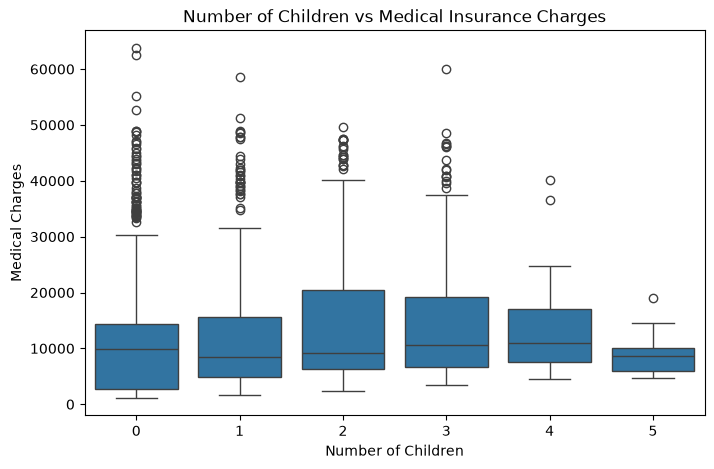

In [27]:
# Plot number of children against medical charges
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="children", y="charges")

plt.title("Number of Children vs Medical Insurance Charges")
plt.xlabel("Number of Children")
plt.ylabel("Medical Charges")
plt.show()

### Number of Children and Medical Charges
The boxplot shows that medical charges vary across the different numbers of children. The number of children will therefore be considered as a potential predictor and assessed further during feature selection.

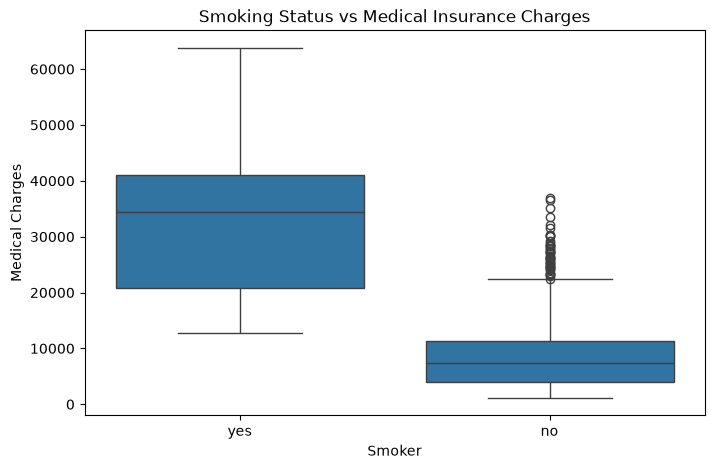

In [28]:
# Compare medical charges between smokers and non-smokers

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Smoking Status vs Medical Insurance Charges")
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.show()

### Smoking Status and Medical Charges

This helps us determine whether smoking status is associated with different charge levels.The boxplot shows a clear difference in medical charges between smokers and non-smokers. Smokers have higher medical charges than non-smokers.
This suggests that smoking status may be an important predictor of medical charges and should be included in the feature selection process.

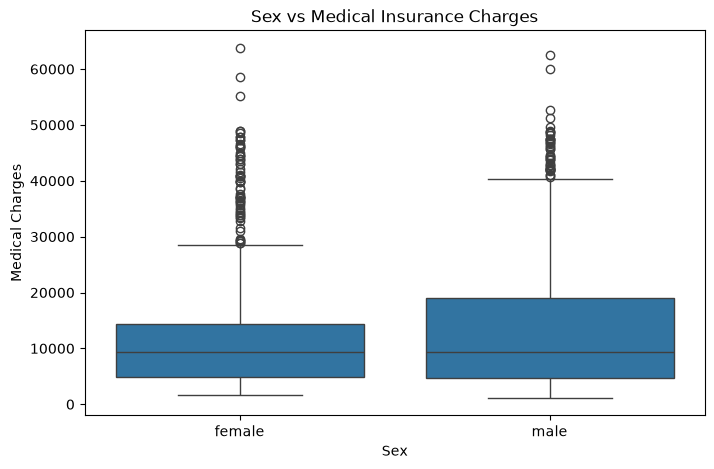

In [29]:
# Compare medical charges between males and females

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sex", y="charges")

plt.title("Sex vs Medical Insurance Charges")
plt.xlabel("Sex")
plt.ylabel("Medical Charges")
plt.show()

This helps us determine whether sex may be associated with different charge levels. The distributions of medical charges for males and females show some overlap. This suggests that sex may have a relatively limited effect on predicting charges compared with some of the other variables.

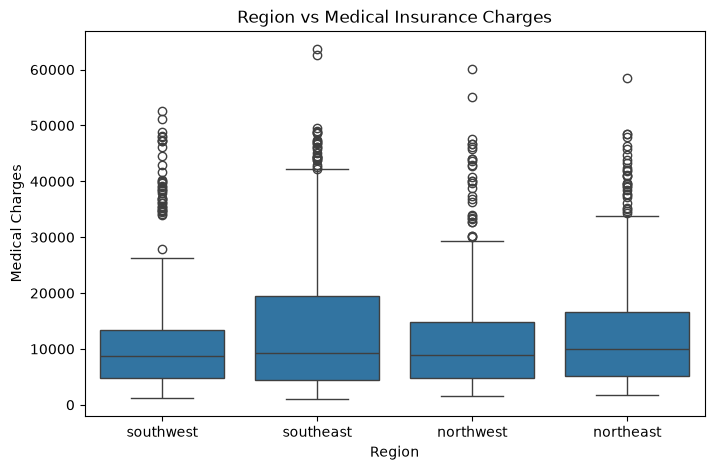

In [30]:
# Compare medical charges across the different regions
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="region", y="charges")

plt.title("Region vs Medical Insurance Charges")
plt.xlabel("Region")
plt.ylabel("Medical Charges")
plt.show()

### Region vs Medical Insurance Charges

This was done to see whether region could be associated with different charge levels. The boxplot shows some differences in medical charges across the four regions. Region will be  initially included as a potential predictor.


In [31]:
# Calculate correlations between the numerical variable

correlation_matrix = df[["age", "bmi", "children", "charges"]].corr()

correlation_matrix

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


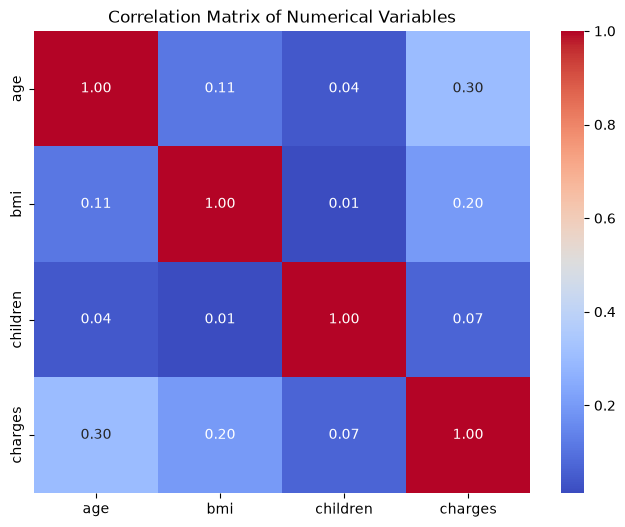

In [32]:
# Visualise the correlations between the numerical variables

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

### Correlation Analysis

The correlation results show that age has the strongest numerical relationship with medical charges (r = 0.298), followed by bmi (r = 0.198). The relationship between the number of children and charges is very weak (r = 0.067). The numerical predictors also have low correlations with one another.

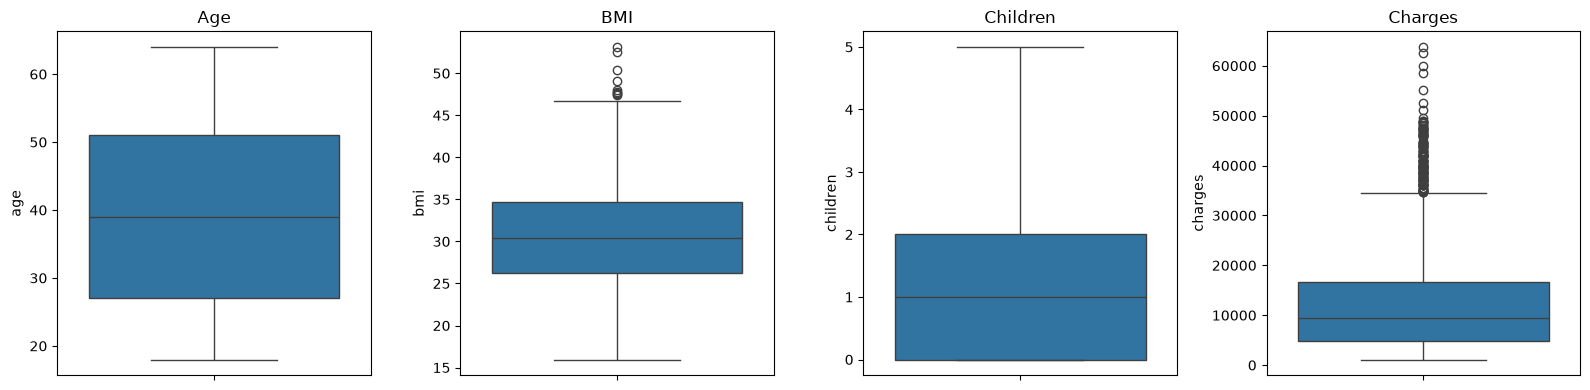

In [33]:
# Plot boxplots for the numerical variables to identify potential outliers

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

sns.boxplot(y=df["age"], ax=axes[0])
axes[0].set_title("Age")

sns.boxplot(y=df["bmi"], ax=axes[1])
axes[1].set_title("BMI")

sns.boxplot(y=df["children"], ax=axes[2])
axes[2].set_title("Children")

sns.boxplot(y=df["charges"], ax=axes[3])
axes[3].set_title("Charges")

plt.tight_layout()
plt.show()

### Outlier analysis

Boxplots were used to identify unusually high or low observations in the numerical variables. Some observations, like for medical charges, go above the main concentration of the data.

In [34]:
# Convert categorical variables into numerical dummy variables
df_model = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

# Display the first five rows of the prepared dataset
df_model.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


### Encoding
The categorical variables were converted into numerical dummy variables so that they could be used by the Linear Regression algorithm. drop_first=True was used to remove one category from each categorical variable


In [35]:
# Separate the target variable from the predictor variables

X = df_model.drop("charges", axis=1)
y = df_model["charges"]

# Display the predictor columns
X.columns

Index(['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest',
       'region_southeast', 'region_southwest'],
      dtype='str')

In [36]:
# Import statsmodels for statistical regression analysis to examine p-values for each predictor

import statsmodels.api as sm

# Add a constant term to represent the intercept in the regression model
X_with_constant = sm.add_constant(X)

# Fit the initial regression model using all candidate predictors
model_full = sm.OLS(y, X_with_constant).fit()

# Display the regression results, including the p-values
model_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     500.0
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:38:19   Log-Likelihood:                -13538.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1328   BIC:                         2.714e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.194e+04    988.227    -12.079      0.000   -1.39e+04   -9997.900
age                256.7646     11.912     21.555      0.000     233.396     280.133
bmi                339.2504     28.611     11.857      0.000     283.122     395.379
children           474.8205    137.897      3.443      0.001     204.301     745.340
sex_male          -129.4815    333.195     -0.389      0.698    -783.128     524.165
smoker_yes        2.385e+04    413.348     57.693      0.000     2.3e+04    2.47e+04
region_northwest  -349.2265    476.824     -0.732      0.464   -1284.637     586.183
region_southeast -1035.2656    478.867     -2.162      0.031   -1974.684     -95.847
region_southwest  -960.0814    478.106     -2.008      0.045   -1898.007     -22.156
==============================================================================
Omnibus:                      299.816   Durbin-Watson:                   2.089
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              716.552
Skew:                           1.211   Prob(JB):                    2.53e-156
Kurtosis:                       5.646   Cond. No.                         311.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [37]:
# Remove sex because its p-value is greater than 0.05

X_selected = X.drop("sex_male", axis=1)

# Add the constant term for the intercept
X_selected_constant = sm.add_constant(X_selected)

# Refit the regression model after removing sex
model_selected = sm.OLS(y, X_selected_constant).fit()

# Display the updated regression results
model_selected.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     571.8
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:38:20   Log-Likelihood:                -13538.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1329   BIC:                         2.713e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.199e+04    979.209    -12.242      0.000   -1.39e+04   -1.01e+04
age                256.8751     11.905     21.577      0.000     233.520     280.230
bmi                338.7325     28.571     11.856      0.000     282.683     394.782
children           473.8629    137.831      3.438      0.001     203.473     744.253
smoker_yes        2.384e+04    412.038     57.847      0.000     2.3e+04    2.46e+04
region_northwest  -348.2514    476.665     -0.731      0.465   -1283.349     586.846
region_southeast -1034.6268    478.711     -2.161      0.031   -1973.739     -95.515
region_southwest  -959.4167    477.950     -2.007      0.045   -1897.036     -21.798
==============================================================================
Omnibus:                      300.175   Durbin-Watson:                   2.090
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              718.139
Skew:                           1.211   Prob(JB):                    1.14e-156
Kurtosis:                       5.650   Cond. No.                         308.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [38]:
# Remove all region dummy variables to test whether region contributes

X_no_region = X_selected.drop(
    ["region_northwest", "region_southeast", "region_southwest"],
    axis=1
)

# Add the constant term for the intercept
X_no_region_constant = sm.add_constant(X_no_region)

# Fit the model without the region variables
model_no_region = sm.OLS(y, X_no_region_constant).fit()

# Display the updated regression results
model_no_region.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     996.5
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:38:23   Log-Likelihood:                -13541.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1332   BIC:                         2.712e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -1.21e+04    942.630    -12.835      0.000   -1.39e+04   -1.02e+04
age          257.7728     11.910     21.644      0.000     234.409     281.137
bmi          321.8708     27.388     11.752      0.000     268.143     375.599
children     472.9751    137.879      3.430      0.001     202.492     743.458
smoker_yes  2.381e+04    411.414     57.875      0.000     2.3e+04    2.46e+04
==============================================================================
Omnibus:                      300.944   Durbin-Watson:                   2.088
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              719.880
Skew:                           1.215   Prob(JB):                    4.79e-157
Kurtosis:                       5.650   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [39]:
# Select the predictors that were statistically significant

X_final = df_model[["age", "bmi", "children", "smoker_yes"]]

# Display the selected predictors
X_final.head()

,age,bmi,children,smoker_yes
0,19,27.900,0,1
1,18,33.770,1,0
2,28,33.000,3,0
3,33,22.705,0,0
4,32,28.880,0,0


### Feature Selection

A full regression model was initially fitted using all available predictors. P-values were examined to identify variables that were statistically significant at the 5% significance level.
The sex_male variable had a p-value greater than 0.05, indicating that it was not statistically significant in the full model. It was therefore removed and the model was refitted.
The region variables were then assessed as a group. Removing the region variables resulted in only a very small reduction in Rsquared, from approximately 0.751 to 0.750, while the adjusted Rsquared remained approximately 0.749.
Age, bmi, number of children and smoking status were selected as the final predictors. Region and sex were excluded in this dataset.

In [40]:
# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# 80% is used to train the model and 20% is reserved for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.20,
    random_state=42
)

# Check the number of observations in each set
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1069, 4)
Testing set: (268, 4)


### Train/test split
The cleaned dataset was divided into training and testing sets. 80% of the observations were used to train the model and 20% were reserved for testing.This allows the model to be evaluated on observations that were not used during training.

In [41]:
# Import the Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model using the default parameters
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

# Display the model intercept and coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: -11256.749134660182
Coefficients: [  249.191292     305.26740368   537.9721959  23042.50723793]


A Linear Regression model was trained using age, bmi, number of children and smoking status as predictors.The coefficients provide an estimate of how the predicted medical charge changes when each predictor increases by one unit, while the other predictors are held constant.

Age: For each additional year of age, predicted charges increase by approximately 249.19 charge units, keeping other variables constant.

bmi: For each one-unit increase in bmi, predicted charges increase by approximately 305.27 charge units, keeping the other variables constant.

Children: Each additional child is associated with an increase of approximately 537.97 charge units, keeping the other variables constant.

Smoking status: Being a smoker is associated with approximately 23042.51 higher charge units compared with a non-smoker, holding the other variables constant.This variable has the largest coefficient which means that it is an important predictor of medical charges in this dataset.

In [42]:
# Import metrics used to evaluate regression performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions for the unseen test data
y_pred = model.predict(X_test)

# Calculate the evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display the model performance
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 4198.592612356368
Root Mean Squared Error (RMSE): 5992.875059638208
R-squared (R²): 0.8045531086669286


### Model Evaluation
he model was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared.
The MAE indicates that the model's predictions differ from the actual medical charges by approximately 4198.59 charge units on average.
The RMSE is higher than the MAE because RMSE gives greater weight to larger prediction errors.
The Rsquared value of 0.805 indicates that approximately 80.5% of the variation in medical charges in the test data is explained by the selected predictors.This model has strong level of predictive performance.

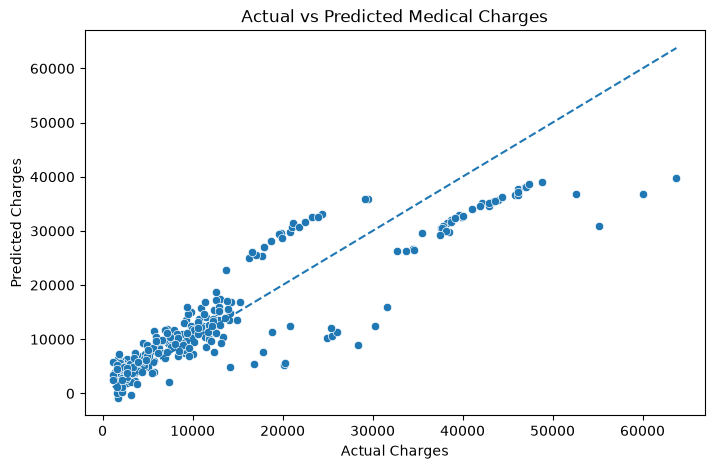

In [43]:
# Compare the actual charges with the model's predicted charges

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_test, y=y_pred)

# Add a reference line showing where predicted values would equal actual values
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Medical Charges")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.show()

This plot is used to compare the model's predictions with observed medical charges.Data points that are closer to the line show predictions that are closer to the actual values. This plot also show how well thr model individual observations and helps identify observations where the prediction error may be large.

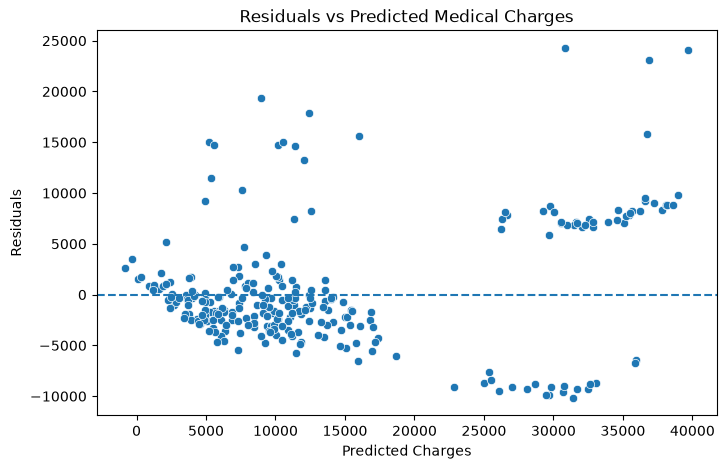

In [44]:
# Calculate the residuals from the test predictions
# Residuals show the difference between the actual and predicted charges
residuals = y_test - y_pred

# Plot residuals against the predicted charges
# A reasonable model should show residuals scattered around zero
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)

# Add a horizontal reference line at zero
plt.axhline(y=0, linestyle="--")

plt.title("Residuals vs Predicted Medical Charges")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.show()

### Residual Analysis

The residuals are not completely randomly scattered around zero and there are some large errors. This suggests that the model does not perfectly capture all patterns in the data. Therefore, the model can be improved and a revised model will be considered

In [48]:
# Apply a log transformation to the target variable to reduce effect of right skewed charges
y_log = np.log1p(y)

# Split the transformed target using the same predictors
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_final,
    y_log,
    test_size=0.20,
    random_state=42
)

# Create and train the revised Linear Regression model
revised_model = LinearRegression()
revised_model.fit(X_train_log, y_train_log)

# Generate predictions on the test data
y_pred_log = revised_model.predict(X_test_log)

# Convert predictions back to the original charge scale
y_pred_revised = np.expm1(y_pred_log)

In [50]:
# Evaluate the revised model using the same metrics as the original model
revised_mae = mean_absolute_error(y_test, y_pred_revised)
revised_rmse = np.sqrt(mean_squared_error(y_test, y_pred_revised))
revised_r2 = r2_score(y_test, y_pred_revised)

# Display the revised model performance
print("Revised MAE:", revised_mae)
print("Revised RMSE:", revised_rmse)
print("Revised R-squared:", revised_r2)

Revised MAE: 3870.7272151489674
Revised RMSE: 7182.822322314769
Revised R-squared: 0.7192313800190893


### Comparison of Models

The revised model produced a lower MAE of 3870.73 but its RMSE increased to 7182.82 and its Rsquared decreased to 0.719.
The original model performed better because it had a higher Rsquared and lower RMSE. Therefore, the original model will be retained as the final model.

### Final Model Selection
The original linear regression model will be retained as the final model. It achieved a lower RMSE of 5,992.88 and a higher R² of 0.805 compared with the revised model. Although the revised model had a lower MAE, the original model explained more variation in medical charges and had smaller overall prediction errors. Therefore, the original model is considered more suitable for predicting medical charges.